# 01 - Exploratory Data Analysis (EDA)

**Objective:** understand the structure of the IEEE-CIS dataset, the class imbalance, missing values, and how fraud behaves over time, before modeling.

In [1]:
import sys
sys.path.append("..")  # para importar src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_ieee, save_processed

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

## 1. Loading and merging
A *left join* is used because not all transactions have identity information.

In [2]:
df = load_ieee("../data/raw")
df.head()

Loading train_transaction.csv ...
Memory: 1791.7 MB -> 932.8 MB (48% lower)
Loading train_identity.csv ...
Memory: 56.5 MB -> 43.3 MB (23% lower)
Final Dataset: 590,540 rows x 435 columns


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,...,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,has_identity
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,NotFound,NaN,-480.0,New,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,1


In [3]:
# Guardamos en parquet para no volver a leer los CSV 
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_parquet("../data/processed/train_merged.parquet", index=False)

## 2. Overview

In [4]:
df.shape, df.dtypes.value_counts()

((590540, 435),
 float32    399
 str         31
 int32        2
 int8         2
 int16        1
 Name: count, dtype: int64)

## 3. Target variable and class imbalance

Fraud rate: 3.50%  |  Fraud cases: 20,663


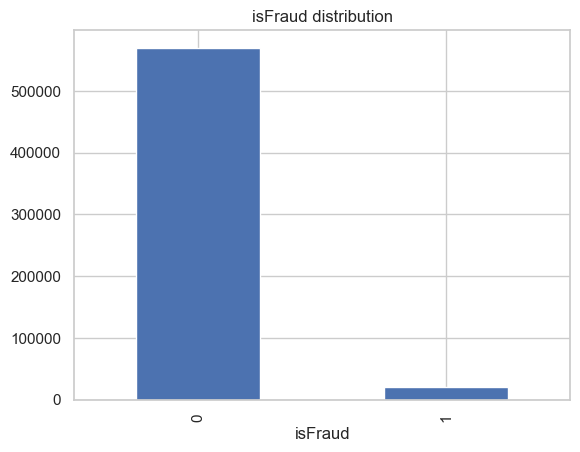

In [5]:
fraud_rate = df["isFraud"].mean()
print(f"Fraud rate: {fraud_rate:.2%}  |  Fraud cases: {df['isFraud'].sum():,}")
df["isFraud"].value_counts().plot(kind="bar", title="isFraud distribution")
plt.show()

## 4. Null values

In [6]:
null_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(f"Columns with >50% null values: {(null_pct > 50).sum()} out of {df.shape[1]}")
null_pct.head(25)

Columns with >50% null values: 214 out of 435


id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
D8       87.312290
id_10    87.312290
D9       87.312290
id_30    86.865411
id_32    86.861855
dtype: float64

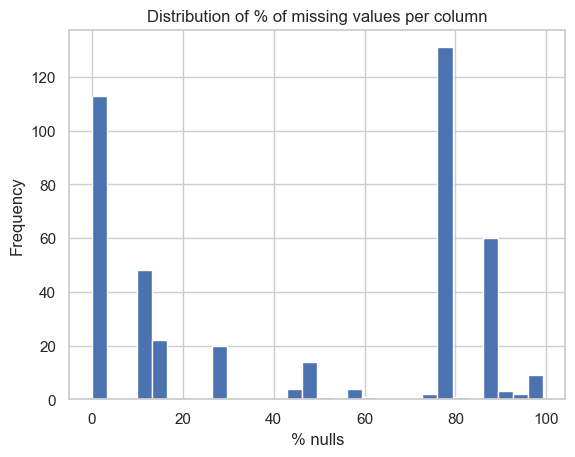

In [7]:
null_pct.plot(kind="hist", bins=30, title="Distribution of % of missing values per column")
plt.xlabel("% nulls"); plt.show()

## 5. Transaction amount (`TransactionAmt`)

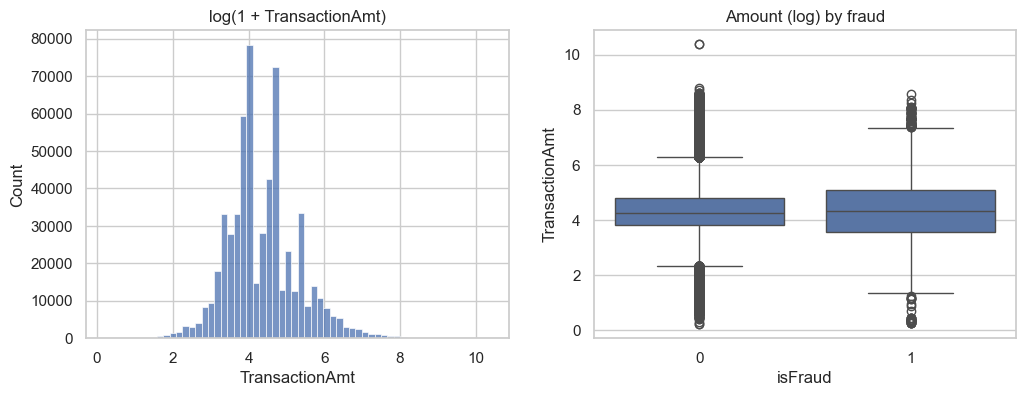

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511658,239.395081,0.251,43.970001,68.5,120.0,31937.390625
1,20663.0,149.244766,232.212158,0.292,35.043999,75.0,161.0,5191.000000


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(df["TransactionAmt"]), bins=60, ax=ax[0])
ax[0].set_title("log(1 + TransactionAmt)")
sns.boxplot(data=df, x="isFraud", y=np.log1p(df["TransactionAmt"]), ax=ax[1])
ax[1].set_title("Amount (log) by fraud")
plt.show()
df.groupby("isFraud")["TransactionAmt"].describe()

## 6. Fraud over time
`TransactionDT` is the number of seconds since an **unknown** reference point, so we can only talk about relative days and hours.

C:\Users\Carlos\AppData\Local\Temp\ipykernel_5776\2953428690.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["day"] = df["TransactionDT"] // (24 * 3600)
C:\Users\Carlos\AppData\Local\Temp\ipykernel_5776\2953428690.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["hour"] = (df["TransactionDT"] // 3600) % 24


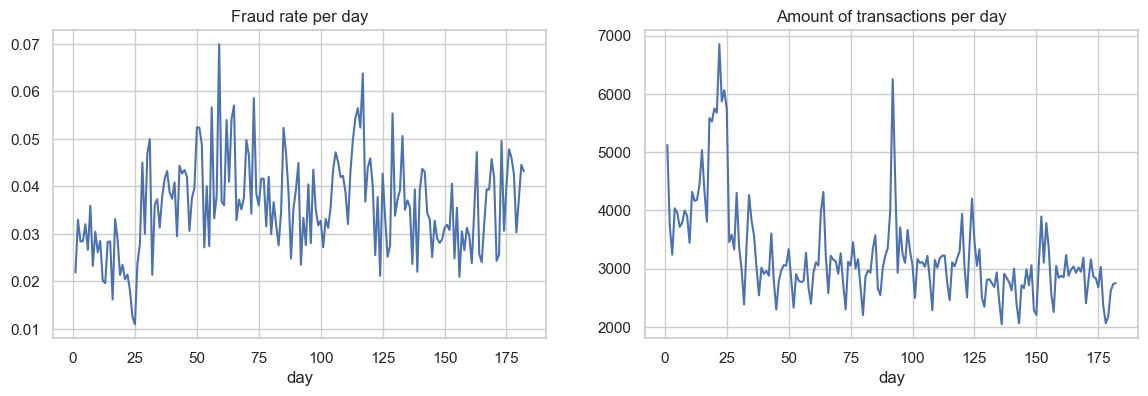

In [9]:
df["day"] = df["TransactionDT"] // (24 * 3600)
df["hour"] = (df["TransactionDT"] // 3600) % 24

daily = df.groupby("day")["isFraud"].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
daily["mean"].plot(ax=ax[0], title="Fraud rate per day")
daily["size"].plot(ax=ax[1], title="Amount of transactions per day")
plt.show()

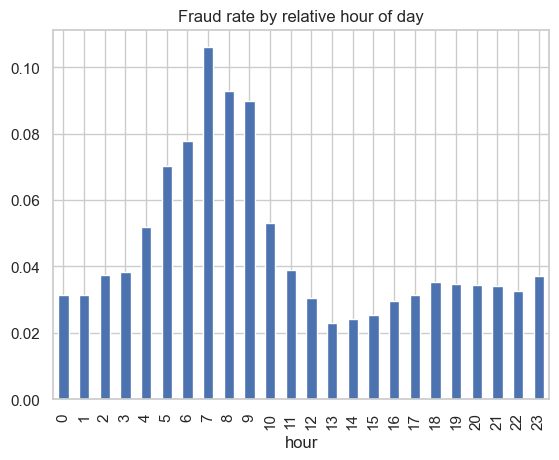

In [10]:
df.groupby("hour")["isFraud"].mean().plot(kind="bar", title="Fraud rate by relative hour of day")
plt.show()

## 7. Key categorical variables

In [11]:
for col in ["ProductCD", "card4", "card6", "DeviceType"]:
    print(df.groupby(col, observed=True)["isFraud"].agg(["mean", "size"]).round(4), "\n")

             mean    size
ProductCD                
C          0.1169   68519
H          0.0477   33024
R          0.0378   37699
S          0.0590   11628
W          0.0204  439670 

                    mean    size
card4                           
american express  0.0287    8328
discover          0.0773    6651
mastercard        0.0343  189217
visa              0.0348  384767 

                   mean    size
card6                          
charge card      0.0000      15
credit           0.0668  148986
debit            0.0243  439938
debit or credit  0.0000      30 

              mean   size
DeviceType               
desktop     0.0652  85165
mobile      0.1017  55645 



## 8. Does having identity information matter?

In [12]:
df.groupby("has_identity")["isFraud"].agg(["mean", "size"])

,mean,size
has_identity,,
0,0.020939,446307
1,0.078470,144233


## 9. Preliminary conclusions

**Structure and class imbalance**
- The dataset has 590,540 transactions and 435 columns, with 3.50% fraud (20,663 cases). It is heavily imbalanced, so accuracy is not a useful metric; PR-AUC and cost analysis will be used instead.

**Missing values**
- 214 of 435 columns have more than 50% missing values. The emptiest ones are the identity columns (`id_*`), `dist2`, and several `D` columns.
- Decision: do not impute blindly. Models that handle missing values natively (LightGBM) will be used, since the absence of data can be informative.

**Amount (`TransactionAmt`)**
- The mean is similar across classes (134 non-fraud vs 149 fraud), but fraud is more spread out: lower 25th percentile (35 vs 44) and higher 75th percentile (161 vs 120).
- Amount alone does not separate the classes well. There is an outlier of ~32,000 in non-fraud.

**Categorical variables**
- `ProductCD` is highly discriminative: C has 11.7% fraud and W only 2.0%, even though W accounts for 74% of transactions.

**Identity**
- Only ~24% of transactions have identity information, but their fraud rate is 7.85% versus 2.09% without identity (almost 4 times higher).
- `has_identity` is a useful signal, but not a causal one: it probably reflects different purchase flows. We need to verify that it remains stable over time.

**Temporality**
- The data covers ~180 relative days (the actual origin date is unknown).
- The daily fraud rate is noisy and shows spikes around days ~60 and ~120. Some relative hours have a higher rate, peaking at hour 7, and with a notably higher magnitude than the rest of the day between hours 4 and 10.
- Implication: validation must be temporal and the splits must account for the spikes.

**Next steps**
- Define temporal splits (notebook 02), build a baseline, and work on feature engineering.